# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

**Автор:** Ибрагимов Шамиль

**Дата:** 13.10.2026

**Использованные источники и инструменты:**
- Python
- Google Colab
- pandas
- matplotlib
- Scrape This Site — источник статистических данных NHL
- ChatGPT — объяснение методов анализа данных и проверка кода


In [26]:
# Ваши импорты и настройки
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [27]:
# 1.1. Ваш код
# Добавьте ячейки при необходимости.
df = pd.read_csv("Data/hockey_raw.csv")

print("Первые пять строк таблицы:")
display(df.head())

print("Размер таблицы:", df.shape)

print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Первые пять строк таблицы:


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


Размер таблицы: (582, 9)
Количество строк: 582
Количество столбцов: 9


**Ответ 1.1:**
Таблица содержит 582 строки и 9 столбцов.
 Каждая строка представляет результаты одной хоккейной команды НХЛ за определенный сезон.
 В таблице указаны название команды, год проведения сезона, количество побед, поражений, поражений в овертайме, процент побед, количество забитых и пропущенных голов, а также разница между ними.
 Таким образом, одна и та же команда может быть представлена в таблице несколько раз, поскольку данные относятся к разным сезонам.

## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [28]:
# Вывод названий и типов столбцов
print("Названия и типы столбцов:")
print(df.dtypes)

# Количество уникальных команд
print("\nКоличество уникальных команд:", df["team"].nunique())

# Количество уникальных годов
print("Количество уникальных годов:", df["year"].nunique())

# Проверка повторений пары team и year
duplicates = df.duplicated(subset=["team", "year"])

print("\nКоличество повторений пары team и year:", duplicates.sum())

Названия и типы столбцов:
team              object
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object

Количество уникальных команд: 35
Количество уникальных годов: 21

Количество повторений пары team и year: 0


**Ответ 1.2:**

В таблице представлены 35 уникальных команд и 21 сезон.
Столбец team имеет строковый тип данных (object). Столбцы year, wins, losses, goals_for, goals_against, goal_diff имеют целочисленный тип (int64). Столбцы ot_losses и win_rate имеют вещественный тип (float64).
Тип float64 у ot_losses объясняется наличием пропущенных значений.
Проверка пары team и year показала 0 повторений. Это означает, что каждая команда представлена не более одного раза в рамках одного сезона.
Следовательно, по проверенному признаку дубликатов нет, а каждая строка соответствует отдельному наблюдению «команда — сезон».


## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [29]:
# 1.3. Ваш код
# 1. Количество пропусков в каждом столбце
missing_count = df.isna().sum()

print("Количество пропусков по столбцам:")
print(missing_count)


# 2. Процент пропусков в каждом столбце
missing_percent = df.isna().mean() * 100

print("\nПроцент пропусков по столбцам:")
print(missing_percent.round(2))


# 3. Количество пропусков ot_losses по годам
missing_by_year = df.groupby("year")["ot_losses"].apply(
    lambda x: x.isna().sum()
)

print("\nКоличество пропусков ot_losses по годам:")
print(missing_by_year)

Количество пропусков по столбцам:
team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

Процент пропусков по столбцам:
team              0.00
year              0.00
wins              0.00
losses            0.00
ot_losses        38.49
win_rate          0.00
goals_for         0.00
goals_against     0.00
goal_diff         0.00
dtype: float64

Количество пропусков ot_losses по годам:
year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999     0
2000     0
2001     0
2002     0
2003     0
2005     0
2006     0
2007     0
2008     0
2009     0
2010     0
2011     0
Name: ot_losses, dtype: int64


**Ответ 1.3:**

В таблице обнаружено 224 пропущенных значения, что составляет 38,49% всех строк. Все пропуски находятся в столбце ot_losses. В остальных столбцах пропущенных значений нет.
При группировке по годам выяснилось, что пропуски встречаются только в сезонах с 1990 по 1998 год включительно. Начиная с 1999 года пропуски отсутствуют.
Я не буду заменять пропуски нулями, поскольку отсутствие информации не означает, что показатель равен нулю. При анализе ot_losses буду использовать только строки с известными значениями. Для анализа других показателей, например win_rate, сохраню все строки, поскольку пропуски в ot_losses не мешают их исследованию

## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [30]:
# 1.4. Ваш код
# Проверка доли побед
invalid_win_rate = ~df["win_rate"].between(0, 1)

print("Некорректная доля побед:", invalid_win_rate.sum())


# Проверка отрицательных значений
columns = [
    "wins",
    "losses",
    "ot_losses",
    "goals_for",
    "goals_against"
]

for column in columns:
    negative_count = (df[column] < 0).sum()
    print(f"Отрицательные значения в {column}: {negative_count}")


# Проверка разницы шайб
invalid_goal_diff = (
    df["goal_diff"] != df["goals_for"] - df["goals_against"]
)

print("Некорректная разница шайб:", invalid_goal_diff.sum())

Некорректная доля побед: 0
Отрицательные значения в wins: 0
Отрицательные значения в losses: 0
Отрицательные значения в ot_losses: 0
Отрицательные значения в goals_for: 0
Отрицательные значения в goals_against: 0
Некорректная разница шайб: 0


**Ответ 1.4:**

Я проверил корректность доли побед, неотрицательность числовых показателей и согласованность разницы шайб.
Проверка показала, что во всех 582 строках win_rate находится в диапазоне от 0 до 1. Отрицательных значений в столбцах wins, losses, ot_losses, goals_for и goals_against не обнаружено.
Во всех строках выполняется равенство goal_diff = goals_for - goals_against. Количество нарушений каждого условия равно нулю.
Если бы я обнаружил нарушения, сначала изучил бы соответствующие строки и сравнил значения с первоисточником. После подтверждения ошибки исправил бы значение при наличии достоверной информации. Если восстановить правильное значение невозможно, пометил бы его как пропущенное или исключил бы наблюдение из конкретного расчёта с объяснением причины.
Исходный CSV я бы сохранил без изменений, а исправления выполнял в копии данных.


## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [31]:
# 2.1. Ваш код
# Вычисление статистических показателей
min_win_rate = df["win_rate"].min()
median_win_rate = df["win_rate"].median()
mean_win_rate = df["win_rate"].mean()
max_win_rate = df["win_rate"].max()

# Вывод результатов
print("Минимальная доля побед:", round(min_win_rate, 3))
print("Медианная доля побед:", round(median_win_rate, 3))
print("Средняя доля побед:", round(mean_win_rate, 3))
print("Максимальная доля побед:", round(max_win_rate, 3))

# Сравнение среднего и медианы
difference = mean_win_rate - median_win_rate

print("\nРазница между средним и медианой:", round(difference, 3))

Минимальная доля побед: 0.119
Медианная доля побед: 0.463
Средняя доля побед: 0.459
Максимальная доля побед: 0.756

Разница между средним и медианой: -0.004


**Ответ 2.1:**

В результате анализа 582 командных сезонов я получил следующие показатели доли побед:

Минимум — 0,119 (11,9%).

Медиана — 0,463 (46,3%).

Среднее — 0,459 (45,9%).

Максимум — 0,756 (75,6%).

Средняя доля побед на 0,004 ниже медианной. Разница небольшая, поэтому оба показателя дают близкую оценку типичного командного сезона: около 46% побед.
При этом минимальное и максимальное значения заметно отличаются, что указывает на существование сезонов с очень низкой и высокой долей побед.
Эти показатели позволяют оценить центральную тенденцию и диапазон значений, но не позволяют определить конкретные команды с лучшими и худшими результатами, проследить изменения по годам или подробно описать форму распределения. Для этого потребуется дальнейший анализ.

## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [32]:
# 2.2. Ваш код
# Группируем данные по годам
season_stats = df.groupby("year").agg(
    teams_count=("team", "nunique"),
    median_wins=("wins", "median"),
    median_win_rate=("win_rate", "median")
)

# Выводим статистику за все годы
print("Статистика по сезонам:")
print(season_stats.to_string())

# Выбираем 1993, 1994 и 1995 годы
selected_years = season_stats.loc[[1993, 1994, 1995]]

print("\nСравнение 1993, 1994 и 1995 годов:")
display(selected_years)

Статистика по сезонам:
      teams_count  median_wins  median_win_rate
year                                           
1990           21         34.0           0.4250
1991           22         35.5           0.4440
1992           24         40.0           0.4760
1993           26         39.0           0.4640
1994           26         20.5           0.4275
1995           26         35.5           0.4330
1996           26         35.0           0.4270
1997           26         35.0           0.4270
1998           27         34.0           0.4150
1999           28         36.0           0.4390
2000           30         36.5           0.4450
2001           30         37.0           0.4510
2002           30         35.5           0.4330
2003           30         38.0           0.4630
2005           30         42.0           0.5120
2006           30         42.5           0.5180
2007           30         41.5           0.5060
2008           30         41.0           0.5000
2009           30

,teams_count,median_wins,median_win_rate
year,,,
1993,26,39.0,0.4640
1994,26,20.5,0.4275
1995,26,35.5,0.4330


**Ответ 2.2:**

Я сгруппировал данные по годам и для каждого сезона вычислил количество уникальных команд, медианное число побед и медианную долю побед.
При сравнении 1993, 1994 и 1995 годов выяснилось, что количество команд оставалось одинаковым — 26.
Медианное число побед составило 39 в 1993 году, 20,5 в 1994 году и 35,5 в 1995 году. Особенно заметно снижение в 1994 году.
При этом медианная доля побед изменилась значительно меньше: 0,4640 в 1993 году, 0,4275 в 1994 году и 0,4330 в 1995 году.
Основная причина резкого сокращения количества побед в 1994 году связана с локаутом NHL в сезоне 1994/95, из-за которого регулярный чемпионат был сокращён до 48 матчей.
Таким образом, при сравнении сезонов разной продолжительности доля побед является более подходящим показателем, чем абсолютное количество побед, поскольку учитывает различия в числе сыгранных матчей.

## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [33]:
# 2.3. Ваш код
# Три сезона с самой высокой долей побед
top_3 = df.nlargest(3, "win_rate")

print("Три самых высоких значения доли побед:")
display(top_3[["team", "year", "win_rate", "wins"]])


# Три сезона с самой низкой долей побед
bottom_3 = df.nsmallest(3, "win_rate")

print("\nТри самых низких значения доли побед:")
display(bottom_3[["team", "year", "win_rate", "wins"]])

Три самых высоких значения доли побед:


,team,year,win_rate,wins
126,Detroit Red Wings,1995,0.756,62
382,Detroit Red Wings,2005,0.707,58
99,Detroit Red Wings,1994,0.688,33



Три самых низких значения доли побед:


,team,year,win_rate,wins
56,Ottawa Senators,1992,0.119,10
60,San Jose Sharks,1992,0.131,11
82,Ottawa Senators,1993,0.167,14


**Ответ 2.3:**

Для поиска трёх лучших и трёх худших командных сезонов я использовал методы nlargest() и nsmallest(), указав столбец win_rate в качестве критерия сравнения.
Три наибольшие доли побед принадлежат Detroit Red Wings: 0,756 в 1995 году, 0,707 в 2005 году и 0,688 в 1994 году.
Три наименьшие доли побед: Ottawa Senators в 1992 году — 0,119, San Jose Sharks в 1992 году — 0,131 и Ottawa Senators в 1993 году — 0,167.
Я убедился, что сравниваю именно долю побед, поскольку сортировка выполнялась по столбцу win_rate, а не wins.
Такое сравнение позволяет учитывать различия в количестве проведённых матчей. Например, Detroit Red Wings в 1994 году одержала 33 победы, но благодаря высокой доле побед 0,688 этот сезон входит в тройку лучших.

## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [34]:
# 2.4. Ваш код
# Выбираем команду
team_name = "Detroit Red Wings"

# Получаем все сезоны выбранной команды
team_data = df[df["team"] == team_name].sort_values("year")

# Количество сезонов
print("Количество сезонов:", len(team_data))

# Выводим результаты по годам
print("\nРезультаты команды по сезонам:")
display(team_data[["team", "year", "wins", "win_rate"]])

# Находим лучший сезон
best_season = team_data.loc[team_data["win_rate"].idxmax()]

# Находим худший сезон
worst_season = team_data.loc[team_data["win_rate"].idxmin()]

print("\nЛучший сезон:")
print("Год:", best_season["year"])
print("Доля побед:", best_season["win_rate"])

print("\nХудший сезон:")
print("Год:", worst_season["year"])
print("Доля побед:", worst_season["win_rate"])

Количество сезонов: 21

Результаты команды по сезонам:


,team,year,wins,win_rate
4,Detroit Red Wings,1990,34,0.425
25,Detroit Red Wings,1991,43,0.537
47,Detroit Red Wings,1992,47,0.560
73,Detroit Red Wings,1993,46,0.548
99,Detroit Red Wings,1994,33,0.688
126,Detroit Red Wings,1995,62,0.756
152,Detroit Red Wings,1996,38,0.463
179,Detroit Red Wings,1997,44,0.537
205,Detroit Red Wings,1998,43,0.524
233,Detroit Red Wings,1999,48,0.585



Лучший сезон:
Год: 1995
Доля побед: 0.756

Худший сезон:
Год: 1990
Доля побед: 0.425


**Ответ 2.4:**

Для анализа я выбрал Detroit Red Wings, поскольку эта команда представлена в 21 сезоне, что соответствует условию задания.
После фильтрации данных по названию команды и сортировки по годам я определил лучший и худший сезоны по показателю win_rate.
Максимальная доля побед составила 0,756 (75,6%) в 1995 году, когда команда одержала 62 победы.
Минимальная доля побед составила 0,425 (42,5%) в 1990 году, когда команда одержала 34 победы.
Разница между максимальной и минимальной долями побед составляет 0,331, или 33,1 процентного пункта.
Сравнивать результаты только по названию команды неудобно, поскольку одна команда встречается в таблице несколько раз и её показатели меняются от сезона к сезону.
Поэтому для однозначного определения наблюдения необходимо учитывать одновременно название команды и год.

## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

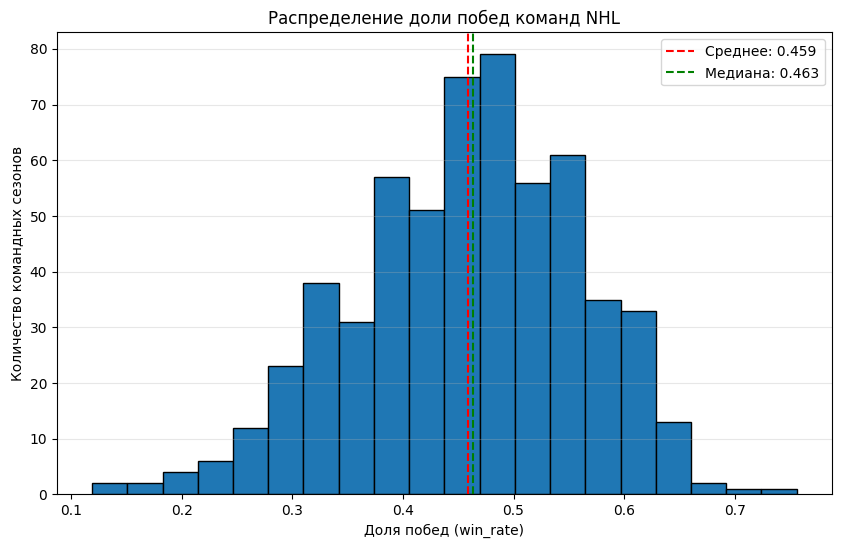

In [35]:
# 3.1. Ваш код
# Создаём область для графика
plt.figure(figsize=(10, 6))

# Строим гистограмму
plt.hist(
    df["win_rate"],
    bins=20,
    edgecolor="black"
)

# Добавляем линии среднего и медианы
plt.axvline(
    mean_win_rate,
    color="red",
    linestyle="--",
    label=f"Среднее: {mean_win_rate:.3f}"
)

plt.axvline(
    median_win_rate,
    color="green",
    linestyle="--",
    label=f"Медиана: {median_win_rate:.3f}"
)

# Подписываем график
plt.title("Распределение доли побед команд NHL")
plt.xlabel("Доля побед (win_rate)")
plt.ylabel("Количество командных сезонов")

# Отображаем легенду
plt.legend()

# Добавляем сетку
plt.grid(axis="y", alpha=0.3)

# Показываем график
plt.show()

**Ответ 3.1:**

Я построил гистограмму распределения win_rate для всех 582 командных сезонов, разделив диапазон значений на 20 интервалов.
По графику видно, что основная масса наблюдений сосредоточена приблизительно в диапазоне от 0,35 до 0,60. Наиболее высокие столбцы расположены около 0,45–0,50.
Это согласуется с результатами задания 2.1: средняя доля побед равна 0,459, а медианная — 0,463.
Среднее и медиана отличаются всего на 0,004 и расположены на графике практически рядом.
На краях распределения наблюдений значительно меньше. Очень низкие и очень высокие доли побед встречаются относительно редко.
Следовательно, для большинства представленных командных сезонов характерна доля побед в центральной части шкалы, приблизительно около 40–55%.

## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

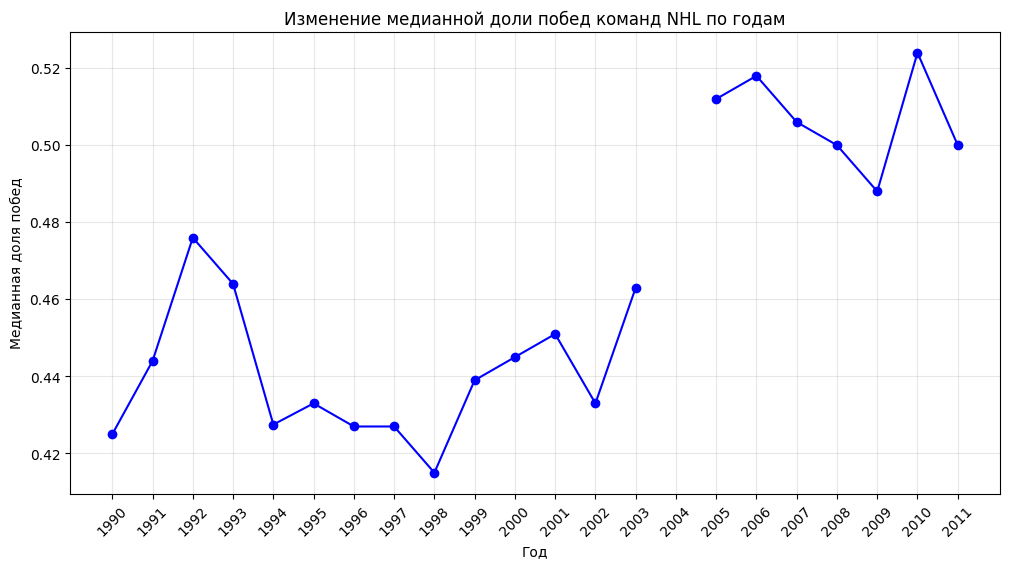

Годы без данных: [2004]

Сравнение 2009, 2010 и 2011 годов:
year
2009    0.488
2010    0.524
2011    0.500
Name: median_win_rate, dtype: float64


In [36]:
# 3.2. Ваш код
# Получаем медианную долю побед по годам
median_by_year = season_stats["median_win_rate"]

# Определяем полный диапазон годов
all_years = range(
    df["year"].min(),
    df["year"].max() + 1
)

# Добавляем отсутствующие годы как NaN
median_by_year = median_by_year.reindex(all_years)

# Создаём график
plt.figure(figsize=(12, 6))

plt.plot(
    median_by_year.index,
    median_by_year.values,
    marker="o",
    linestyle="-",
    color="blue"
)

# Подписываем график
plt.title("Изменение медианной доли побед команд NHL по годам")
plt.xlabel("Год")
plt.ylabel("Медианная доля побед")

# Добавляем сетку
plt.grid(True, alpha=0.3)

# Показываем все годы на горизонтальной оси
plt.xticks(list(all_years), rotation=45)

plt.show()

# Выводим годы без данных
missing_years = median_by_year[
    median_by_year.isna()
].index.tolist()

print("Годы без данных:", missing_years)

# Сравниваем выбранный год с соседними
print("\nСравнение 2009, 2010 и 2011 годов:")
print(season_stats.loc[[2009, 2010, 2011], "median_win_rate"])

**Ответ 3.2:**

Я построил линейный график изменения медианной доли побед команд NHL по годам, используя результаты группировки из задания 2.2.
На графике видно, что медианная доля побед изменялась от сезона к сезону. В период 1990–2003 годов значения преимущественно находились ниже 0,48, а в 2005–2011 годах составляли приблизительно 0,49–0,52.
В качестве локального максимума я выделил 2010 год. Медианная доля побед в этом году составила 0,524, тогда как в 2009 году она равнялась 0,488, а в 2011 году — 0,500.
Таким образом, показатель 2010 года превышает значения соседних лет на 0,036 и 0,024 соответственно.
В наборе данных отсутствует 2004 год. При построении графика я сохранил этот год в последовательности, но обозначил его значение как пропущенное (NaN). Благодаря этому на графике имеется разрыв между 2003 и 2005 годами, а отсутствующие наблюдения не подменяются вымышленными значениями.
График позволяет увидеть изменения медианной доли побед во времени, но сам по себе не объясняет причины этих изменений.

## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

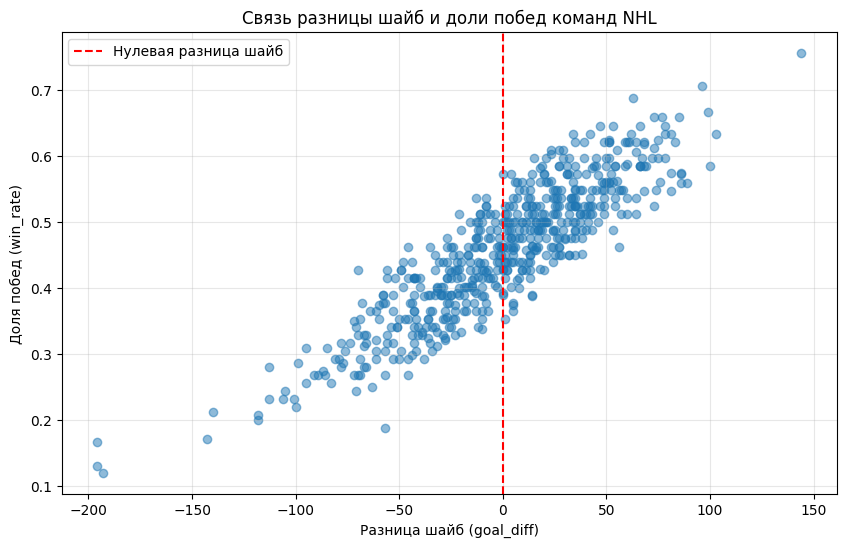

Пример с большой положительной разницей шайб:


,team,year,goal_diff,win_rate
126,Detroit Red Wings,1995,144,0.756


Пример с большой отрицательной разницей шайб:


,team,year,goal_diff,win_rate
60,San Jose Sharks,1992,-196,0.131


Коэффициент корреляции: 0.887
Положительная разница шайб, но доля побед ниже 50%:
96

Отрицательная разница шайб, но доля побед выше 50%:
10

Примеры исключений:


,team,year,goal_diff,win_rate
1,Buffalo Sabres,1990,14,0.388
9,Montreal Canadiens,1990,24,0.487
10,New Jersey Devils,1990,8,0.400
385,Los Angeles Kings,2005,-21,0.512
387,Montreal Canadiens,2005,-4,0.512
398,Tampa Bay Lightning,2005,-8,0.524


In [37]:
# 3.3. Ваш код
# Создаём область графика
plt.figure(figsize=(10, 6))

# Строим диаграмму рассеяния
plt.scatter(
    df["goal_diff"],
    df["win_rate"],
    alpha=0.5
)

# Добавляем линию нулевой разницы шайб
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Нулевая разница шайб"
)

# Подписываем график
plt.title("Связь разницы шайб и доли побед команд NHL")
plt.xlabel("Разница шайб (goal_diff)")
plt.ylabel("Доля побед (win_rate)")

# Добавляем сетку и легенду
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


# Выводим два примера для анализа
print("Пример с большой положительной разницей шайб:")
display(
    df.nlargest(1, "goal_diff")[
        ["team", "year", "goal_diff", "win_rate"]
    ]
)

print("Пример с большой отрицательной разницей шайб:")
display(
    df.nsmallest(1, "goal_diff")[
        ["team", "year", "goal_diff", "win_rate"]
    ]
)

# Рассчитываем корреляцию
correlation = df["goal_diff"].corr(df["win_rate"])

print("Коэффициент корреляции:", round(correlation, 3))


# Проверяем исключения из общей закономерности

positive_diff_low_win_rate = df[
    (df["goal_diff"] > 0) &
    (df["win_rate"] < 0.5)
]

negative_diff_high_win_rate = df[
    (df["goal_diff"] < 0) &
    (df["win_rate"] > 0.5)
]

print("Положительная разница шайб, но доля побед ниже 50%:")
print(len(positive_diff_low_win_rate))

print("\nОтрицательная разница шайб, но доля побед выше 50%:")
print(len(negative_diff_high_win_rate))

print("\nПримеры исключений:")
display(
    pd.concat([
        positive_diff_low_win_rate.head(3),
        negative_diff_high_win_rate.head(3)
    ])[["team", "year", "goal_diff", "win_rate"]]
)

**Ответ 3.3:**

Я построил диаграмму рассеяния, используя goal_diff по горизонтальной оси и win_rate по вертикальной.
На графике наблюдается сильная положительная связь: при увеличении разницы между забитыми и пропущенными шайбами доля побед, как правило, возрастает.
Коэффициент корреляции Пирсона составляет 0,887, что подтверждает наличие сильной положительной линейной связи между показателями.
Например, Detroit Red Wings в 1995 году имела разницу шайб +144 и долю побед 0,756. San Jose Sharks в 1992 году имела разницу шайб −196 и долю побед 0,131.
Однако наличие сильной корреляции не означает, что знак goal_diff безошибочно определяет долю побед. На диаграмме наблюдается разброс точек, поэтому команды с похожей разницей шайб могут иметь разные результаты. Для проверки наличия исключений я дополнительно сравниваю знак goal_diff с условным порогом доли побед 50%.

## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

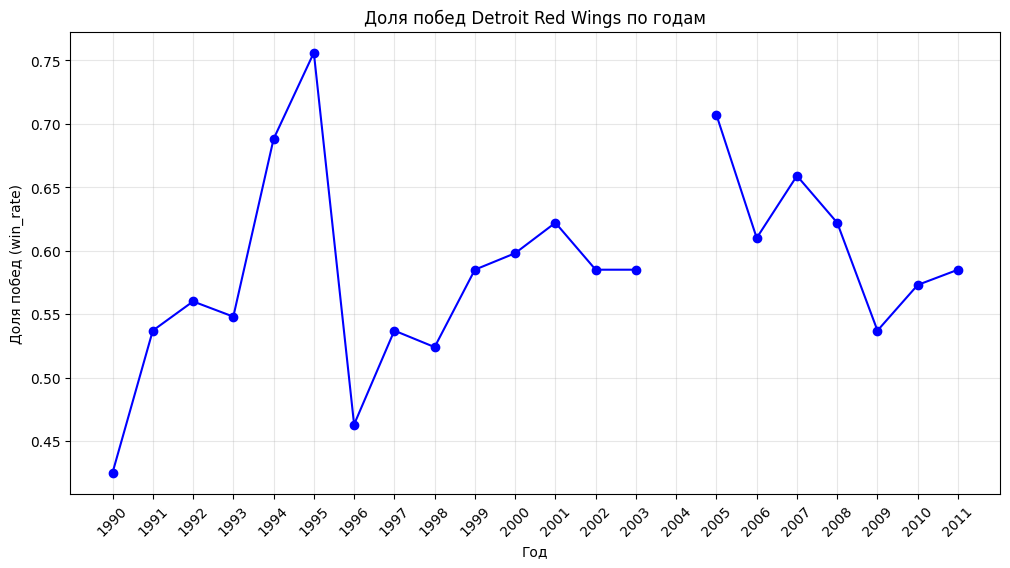

Годы без данных: [2004]

Наибольшее изменение между доступными сезонами:
1995 год: 0.756
1996 год: 0.463
Абсолютная разница: 0.293


In [38]:
# 3.4. Ваш код
# Выбираем Detroit Red Wings
team_name = "Detroit Red Wings"

team_data = df[df["team"] == team_name].sort_values("year")

# Создаём полный диапазон годов
all_years = range(
    team_data["year"].min(),
    team_data["year"].max() + 1
)

# Формируем данные для графика
team_history = team_data.set_index("year")["win_rate"]

# Добавляем отсутствующие годы как NaN
team_history = team_history.reindex(all_years)

# Строим график
plt.figure(figsize=(12, 6))

plt.plot(
    team_history.index,
    team_history.values,
    marker="o",
    linestyle="-",
    color="blue"
)

plt.title("Доля побед Detroit Red Wings по годам")
plt.xlabel("Год")
plt.ylabel("Доля побед (win_rate)")

plt.xticks(list(all_years), rotation=45)
plt.grid(True, alpha=0.3)

plt.show()

# Находим пропущенные годы
missing_years = team_history[team_history.isna()].index.tolist()

print("Годы без данных:", missing_years)

# Находим изменения между соседними доступными сезонами
changes = team_history.dropna().diff().abs()

# Определяем максимальное изменение
year_max_change = changes.idxmax()

# Предыдущий доступный год
previous_year = team_history.dropna().index[
    team_history.dropna().index.get_loc(year_max_change) - 1
]

print("\nНаибольшее изменение между доступными сезонами:")

print(
    previous_year,
    "год:",
    team_history.loc[previous_year]
)

print(
    year_max_change,
    "год:",
    team_history.loc[year_max_change]
)

print("Абсолютная разница:", changes.loc[year_max_change])

**Ответ 3.4:**

Я построил линейный график изменения доли побед Detroit Red Wings за все доступные сезоны с 1990 по 2011 год.
В данных отсутствует 2004 год. Чтобы не создавать ложного впечатления о наличии данных, я добавил пропущенный год в последовательность с помощью reindex(), сохранив для него значение NaN. Поэтому на графике между 2003 и 2005 годами отображается разрыв.
Наибольшее изменение доли побед произошло между 1995 и 1996 годами.
В 1995 году доля побед составляла 0,756 (75,6%), а в 1996 году — 0,463 (46,3%). Таким образом, показатель снизился на 0,293, или 29,3 процентного пункта.
Это показывает, что результаты одной команды могут значительно изменяться от сезона к сезону. Однако по одному графику нельзя установить причины такого изменения.

## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [39]:
# 4.1. Ваш код
# Минимальный и максимальный годы
min_year = df["year"].min()
max_year = df["year"].max()

print("Минимальный год:", min_year)
print("Максимальный год:", max_year)

# Все годы в указанном диапазоне
all_years = set(range(min_year, max_year + 1))

# Годы, присутствующие в таблице
existing_years = set(df["year"].unique())

# Находим отсутствующие годы
missing_years = sorted(all_years - existing_years)

print("\nОтсутствующие годы:", missing_years)
print("Количество отсутствующих годов:", len(missing_years))

Минимальный год: 1990
Максимальный год: 2011

Отсутствующие годы: [2004]
Количество отсутствующих годов: 1


**Ответ 4.1:**

Я проверил последовательность лет между минимальным и максимальным значениями столбца year.
Минимальный год в таблице — 1990, максимальный — 2011. В этом диапазоне отсутствует только 2004 год.
Отсутствие данных связано с отменой сезона NHL 2004/05 из-за локаута.
Пропущенные годы необходимо учитывать при построении линейных графиков, поскольку автоматическое соединение соседних доступных наблюдений может создать ложное впечатление непрерывности данных.
В задании 3.2 я использовал reindex(), чтобы сохранить 2004 год в последовательности и обозначить отсутствующее значение как NaN.
В результате между 2003 и 2005 годами на графике появился разрыв, который показывает, что данные за промежуточный сезон отсутствуют.

## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

In [40]:
# 4.2. Ваш код
# Выбираем команду и интересующие годы
team_name = "Detroit Red Wings"
years = [1993, 1994, 1995]

# Фильтруем таблицу
selected_data = df[
    (df["team"] == team_name) &
    (df["year"].isin(years))
].sort_values("year")

# Выводим результаты
print("Сравнение Detroit Red Wings:")
display(selected_data[["team", "year", "wins", "win_rate"]])

# Определяем год с максимальным количеством побед
best_by_wins = selected_data.loc[
    selected_data["wins"].idxmax()
]

# Определяем год с максимальной долей побед
best_by_rate = selected_data.loc[
    selected_data["win_rate"].idxmax()
]

print("\nЛучший год по количеству побед:", best_by_wins["year"])
print("Лучший год по доле побед:", best_by_rate["year"])

# Выводим статистику из задания 2.2
print("\nМедианные показатели всех команд:")
display(season_stats.loc[years])

Сравнение Detroit Red Wings:


,team,year,wins,win_rate
73,Detroit Red Wings,1993,46,0.548
99,Detroit Red Wings,1994,33,0.688
126,Detroit Red Wings,1995,62,0.756



Лучший год по количеству побед: 1995
Лучший год по доле побед: 1995

Медианные показатели всех команд:


,teams_count,median_wins,median_win_rate
year,,,
1993,26,39.0,0.4640
1994,26,20.5,0.4275
1995,26,35.5,0.4330


**Ответ 4.2:**

Для сравнения я выбрал Detroit Red Wings, поскольку команда представлена во всех трёх рассматриваемых сезонах.
В 1993 году команда одержала 46 побед при доле побед 0,548. В 1994 году количество побед снизилось до 33, но доля побед увеличилась до 0,688. В 1995 году команда одержала 62 победы при доле побед 0,756.
Если сравнивать только количество побед, можно ошибочно заключить, что в 1994 году команда выступила хуже, чем в 1993 году. Однако доля побед показывает противоположную картину: она увеличилась на 14 процентных пунктов.
Это связано с сокращением сезона NHL 1994/95 из-за локаута.
Аналогичную особенность я обнаружил в задании 2.2. Медианное число побед всех команд снизилось с 39 в 1993 году до 20,5 в 1994 году, тогда как медианная доля побед изменилась с 0,4640 до 0,4275.
Таким образом, абсолютное количество побед не всегда подходит для сравнения сезонов разной продолжительности. Доля побед позволяет проводить более корректное сравнение.


## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [41]:
# 4.3. Ваш код
# Ищем команды с положительной разницей шайб,
# но долей побед ниже 50%
interesting_cases = df[
    (df["goal_diff"] > 0) &
    (df["win_rate"] < 0.5)
]

# Сортируем по разнице шайб
interesting_cases = interesting_cases.sort_values(
    "goal_diff",
    ascending=False
)

print("Количество найденных наблюдений:", len(interesting_cases))

print("\nПримеры:")
display(
    interesting_cases[
        ["team", "year", "goal_diff", "win_rate"]
    ].head(10)
)

Количество найденных наблюдений: 96

Примеры:


,team,year,goal_diff,win_rate
152,Detroit Red Wings,1996,56,0.463
123,Chicago Blackhawks,1995,53,0.488
363,Philadelphia Flyers,2003,43,0.488
190,Pittsburgh Penguins,1997,40,0.488
350,Colorado Avalanche,2003,38,0.488
54,New York Islanders,1992,38,0.476
44,Buffalo Sabres,1992,38,0.452
35,Pittsburgh Penguins,1991,35,0.487
78,Montreal Canadiens,1993,35,0.488
215,Philadelphia Flyers,1998,35,0.451


**Ответ 4.3:**

В качестве дополнительного наблюдения я решил проверить, существуют ли командные сезоны с положительной разницей шайб, но долей побед ниже 50%.
Для этого я отфильтровал строки по условиям goal_diff > 0 и win_rate < 0.5. В результате было найдено 96 наблюдений.
Один из наиболее интересных примеров — Detroit Red Wings в 1996 году. Разница шайб команды составляла +56, однако доля побед равнялась 0,463 (46,3%).
Обратить внимание на подобные случаи мне помогло задание 3.3, в котором я исследовал связь между разницей шайб и долей побед с помощью диаграммы рассеяния.
Несмотря на высокую положительную корреляцию между показателями (0,887), конкретный пример показывает, что положительная разница шайб не гарантирует долю побед выше 50%.
Таким образом, результаты уточняют общий вывод: разница шайб тесно связана с долей побед, но не позволяет безошибочно определить успешность отдельного командного сезона.


## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

In [42]:
# 4.4. Ваш код
# Подтверждение первого вывода
print("Корреляция между разницей шайб и долей побед:")
print(round(df["goal_diff"].corr(df["win_rate"]), 3))

# Подтверждение второго вывода
print("\nСравнение Detroit Red Wings:")
display(
    df[
        (df["team"] == "Detroit Red Wings") &
        (df["year"].isin([1993, 1994]))
    ][["team", "year", "wins", "win_rate"]]
)

# Подтверждение ограничения данных
print("\nОтсутствующие годы:", missing_years)

Корреляция между разницей шайб и долей побед:
0.887

Сравнение Detroit Red Wings:


,team,year,wins,win_rate
73,Detroit Red Wings,1993,46,0.548
99,Detroit Red Wings,1994,33,0.688



Отсутствующие годы: [2004]


**Ответ 4.4:**

Вывод 1. Связь между разницей шайб и долей побед.
В задании 3.3 я построил диаграмму рассеяния зависимости win_rate от goal_diff. Коэффициент корреляции Пирсона составил 0,887, что указывает на сильную положительную линейную связь между показателями.
Таким образом, команды с большей положительной разницей шайб обычно выигрывают более высокую долю матчей. Однако эта зависимость не является безошибочной. В задании 4.3 я обнаружил 96 наблюдений, в которых положительная разница шайб сопровождалась долей побед ниже 50%.
Вывод 2. Важность использования доли побед при сравнении сезонов.
В таблице задания 4.2 я сравнил результаты Detroit Red Wings за 1993 и 1994 годы.
В 1993 году команда одержала 46 побед при доле побед 0,548. В 1994 году количество побед снизилось до 33, однако доля побед увеличилась до 0,688.
Следовательно, сравнение только абсолютного количества побед может приводить к ошибочным выводам, особенно если продолжительность сезонов различается. Для более корректного сравнения необходимо учитывать долю побед.
Ограничение данных.
В задании 4.1 я установил, что в наборе данных отсутствует 2004 год, поскольку сезон NHL 2004/05 был отменён из-за локаута.
Это ограничивает анализ временных изменений: невозможно определить результаты команд за отсутствующий сезон. Поэтому при построении линейных графиков я оставлял разрыв между 2003 и 2005 годами, не заменяя отсутствующие значения предполагаемыми.